In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

En la reunión de planificación cada responsable de actividad entrega una única duración (columna `estimacion_entregada`, semanas). Usted, que ha hablado con ellos uno a uno, sabe que cada uno ha dado su **peor caso** (la estimación pesimista) «por si acaso», sin decirlo. Las tres estimaciones reales de cada actividad (optimista, más probable y pesimista) se adjuntan.

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, a, m, b , estimacion_entregada
    ('A'     , '---'      , 1, 3, 5 , 5                   ),
    ('B'     , '---'      , 1, 1, 1 , 1                   ),
    ('C'     , 'A,B'      , 7, 8, 9 , 9                   ),
    ('D'     , 'C'        , 1, 3, 11, 11                  ),
    ('E'     , 'D'        , 2, 4, 12, 12                  ),
    ('F'     , 'C'        , 1, 2, 3 , 3                   ),
    ('G'     , 'D'        , 1, 4, 7 , 7                   ),
    ('H'     , 'E'        , 1, 1, 1 , 1                   ),
    ('I'     , 'F,G,H'    , 1, 1, 1 , 1                   ),
], columns=['activity', 'predecessor', 'a', 'm', 'b', 'estimacion_entregada']).set_index('activity')
datos_enunciado

,predecessor,a,m,b,estimacion_entregada
activity,,,,,
A,---,1,3,5,5
B,---,1,1,1,1
C,"A,B",7,8,9,9
D,C,1,3,11,11
E,D,2,4,12,12
F,C,1,2,3,3
G,D,1,4,7,7
H,E,1,1,1,1
I,"F,G,H",1,1,1,1


> **De: Jefe de proyecto**
> Con las estimaciones entregadas el proyecto sale en 39 semanas. Yo le añado un 10 % y prometo 43 al cliente; así nunca llegamos tarde. Lo del colchón de cada uno no hace falta contarlo, cada cual gestiona su margen.

## Criterio de referencia

Las preguntas del bloque **B** se responden aplicando los criterios siguientes, tomados de la lección 19 (redactados por el curso; cada uno remite a la fuente de la que procede, que no se reproduce). La respuesta se justifica citando el criterio y la fuente, no con una opinión.

- **C8 — Reserva declarada frente a colchón oculto.** Una reserva de contingencia dimensionada con un nivel de confianza y comunicada es una práctica correcta; el mismo margen escondido en las estimaciones individuales, sin decirlo, es retención de información (C4). *(cf. PMBOK, reservas de contingencia; Código Ético del PMI, 5.2.3.)*
- **C4 — Retención de información.** Callar un hecho conocido que la otra parte necesitaría para decidir (un riesgo, una holgura, una discrepancia). *(cf. Código Ético del PMI, 5.3.1 y 5.2.3.)*

Responda a las preguntas: A (cálculo), B (criterio) y C (deliberación).

In [5]:
pregunta_1 = "1. (A) Con las tres estimaciones calcule la duración esperada, la desviación típica del camino crítico y la duración que se cumpliría con probabilidad 0,8 (reserva de contingencia necesaria para ese nivel de confianza).  "
pregunta_2 = "2. (A) Calcule la duración con las estimaciones entregadas y con el 10 % del jefe de proyecto, y compare el margen total oculto con la reserva necesaria. ¿Por qué sumar los peores casos de cada actividad sobrestima tanto?  "
pregunta_3 = "3. (B) ¿Qué criterio distingue el margen que propone el jefe de proyecto de una reserva de contingencia correcta? ¿Qué habría que cambiar en el informe de planificación para que cumpla el criterio?  "
pregunta_4 = "4. (C) ¿Cómo plantearía la planificación al equipo y al cliente? Aplique la rúbrica de la lección.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. (A) Con las tres estimaciones calcule la duración esperada, la desviación típica del camino crítico y la duración que se cumpliría con probabilidad 0,8 (reserva de contingencia necesaria para ese nivel de confianza).  

2. (A) Calcule la duración con las estimaciones entregadas y con el 10 % del jefe de proyecto, y compare el margen total oculto con la reserva necesaria. ¿Por qué sumar los peores casos de cada actividad sobrestima tanto?  

3. (B) ¿Qué criterio distingue el margen que propone el jefe de proyecto de una reserva de contingencia correcta? ¿Qué habría que cambiar en el informe de planificación para que cumpla el criterio?  

4. (C) ¿Cómo plantearía la planificación al equipo y al cliente? Aplique la rúbrica de la lección.  

# Resolución

In [6]:
datos_proyecto = datos_enunciado.copy()
datos_proyecto['duration'] = (datos_proyecto['a'] + 4 * datos_proyecto['m'] + datos_proyecto['b']) / 6
datos_proyecto['standard_deviation'] = (datos_proyecto['b'] - datos_proyecto['a']) / 6
datos_proyecto['variance'] = datos_proyecto['standard_deviation'] ** 2
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
duracion = float(proyecto.duration(datos_proyecto['duration']))
sigma, _ = proyecto.standard_deviation(durations=datos_proyecto['duration'], variances=datos_proyecto['variance'])
T80 = duracion + norm.ppf(0.8) * sigma
reserva = T80 - duracion

In [7]:
proyecto.display_roy_pasos(datos_proyecto['duration'])

**Tiempos mínimos (hacia delante)**

- $T_{\mathrm{Inicio}} = 0$
- $T_{A} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{B} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{C} = \max\{0+3,\ 0+1\} = 3$ &nbsp; (A, B)
- $T_{D} = 3+8 = 11$ &nbsp; (C)
- $T_{F} = 3+8 = 11$ &nbsp; (C)
- $T_{E} = 11+4 = 15$ &nbsp; (D)
- $T_{G} = 11+4 = 15$ &nbsp; (D)
- $T_{H} = 15+5 = 20$ &nbsp; (E)
- $T_{I} = \max\{11+2,\ 15+4,\ 20+1\} = 21$ &nbsp; (F, G, H)
- $T_{\mathrm{Fin}} = 21+1 = 22$ &nbsp; (I)

**Tiempos máximos (hacia atrás)**

- $T_{\mathrm{Fin}}^{*} = T_{\mathrm{Fin}} = 22$
- $T_{I}^{*} = 22-1 = 21$ &nbsp; (Fin)
- $T_{H}^{*} = 21-1 = 20$ &nbsp; (I)
- $T_{G}^{*} = 21-4 = 17$ &nbsp; (I)
- $T_{E}^{*} = 20-5 = 15$ &nbsp; (H)
- $T_{F}^{*} = 21-2 = 19$ &nbsp; (I)
- $T_{D}^{*} = \min\{15-4,\ 17-4\} = 11$ &nbsp; (E, G)
- $T_{C}^{*} = \min\{11-8,\ 19-8\} = 3$ &nbsp; (D, F)
- $T_{B}^{*} = 3-1 = 2$ &nbsp; (C)
- $T_{A}^{*} = 3-3 = 0$ &nbsp; (C)
- $T_{\mathrm{Inicio}}^{*} = \min\{0-0,\ 2-0\} = 0$ &nbsp; (A, B)

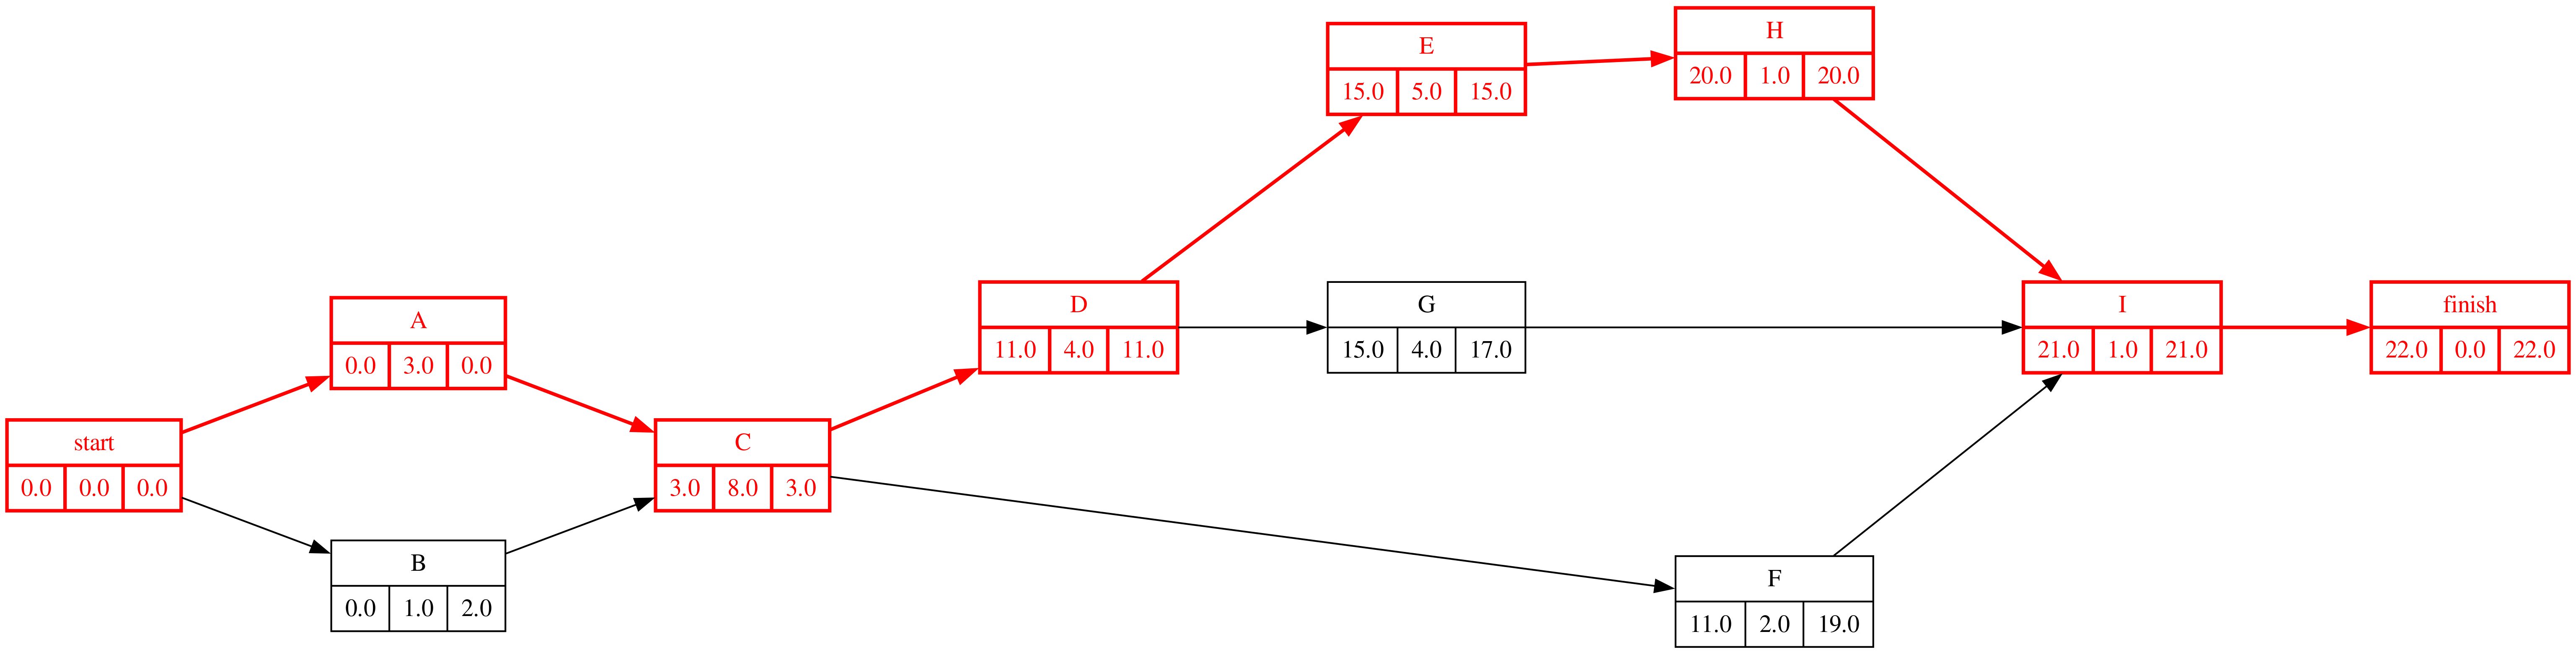

In [8]:
#| fig-cap: "Grafo Roy con las duraciones medias"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. (A) Con las tres estimaciones calcule la duración esperada, la desviación típica del camino crítico y la duración que se cumpliría con probabilidad 0,8 (reserva de contingencia necesaria para ese nivel de confianza).  

In [10]:
#| tbl-cap: "Media y varianza PERT de cada actividad"
#| label: tbl-estimaciones
detalle_estimaciones(datos_enunciado)

,D = (a + 4m + b)/6,σ² = ((b − a)/6)²
A,(1 + 4·3 + 5)/6 = 3.00,((5 − 1)/6)² = 0.444
B,(1 + 4·1 + 1)/6 = 1.00,((1 − 1)/6)² = 0.000
C,(7 + 4·8 + 9)/6 = 8.00,((9 − 7)/6)² = 0.111
D,(1 + 4·3 + 11)/6 = 4.00,((11 − 1)/6)² = 2.778
E,(2 + 4·4 + 12)/6 = 5.00,((12 − 2)/6)² = 2.778
F,(1 + 4·2 + 3)/6 = 2.00,((3 − 1)/6)² = 0.111
G,(1 + 4·4 + 7)/6 = 4.00,((7 − 1)/6)² = 1.000
H,(1 + 4·1 + 1)/6 = 1.00,((1 − 1)/6)² = 0.000
I,(1 + 4·1 + 1)/6 = 1.00,((1 − 1)/6)² = 0.000


In [11]:
#| tbl-cap: "Duración y varianza de cada ruta"
#| label: tbl-rutas
R = proyecto.path_matrix(dummies=False)
display(detalle_rutas(R, datos_proyecto['duration'], 'duración', 2))
detalle_rutas(R, datos_proyecto['variance'], 'varianza', 3)

,actividades,duración = suma,duración
Route_1,A - C - D - E - H - I,A(3.00) + C(8.00) + D(4.00) + E(5.00) + H(1.00...,22.0
Route_2,A - C - D - G - I,A(3.00) + C(8.00) + D(4.00) + G(4.00) + I(1.00...,20.0
Route_3,A - C - F - I,A(3.00) + C(8.00) + F(2.00) + I(1.00) = 14.00,14.0
Route_4,B - C - D - E - H - I,B(1.00) + C(8.00) + D(4.00) + E(5.00) + H(1.00...,20.0
Route_5,B - C - D - G - I,B(1.00) + C(8.00) + D(4.00) + G(4.00) + I(1.00...,18.0
Route_6,B - C - F - I,B(1.00) + C(8.00) + F(2.00) + I(1.00) = 12.00,12.0


,actividades,varianza = suma,varianza
Route_1,A - C - D - E - H - I,A(0.444) + C(0.111) + D(2.778) + E(2.778) + H(...,6.111111
Route_2,A - C - D - G - I,A(0.444) + C(0.111) + D(2.778) + G(1.000) + I(...,4.333333
Route_3,A - C - F - I,A(0.444) + C(0.111) + F(0.111) + I(0.000) = 0.667,0.666667
Route_4,B - C - D - E - H - I,B(0.000) + C(0.111) + D(2.778) + E(2.778) + H(...,5.666667
Route_5,B - C - D - G - I,B(0.000) + C(0.111) + D(2.778) + G(1.000) + I(...,3.888889
Route_6,B - C - F - I,B(0.000) + C(0.111) + F(0.111) + I(0.000) = 0.222,0.222222


In [12]:
Markdown(f'''Duración esperada **{duracion:.2f}** semanas, σ = {sigma:.2f}; con probabilidad 0,8 se termina en **{T80:.2f}** semanas: la reserva de contingencia para ese nivel de confianza es **{reserva:.2f}** semanas (z₀,₈ · σ = 0,84 · {sigma:.2f}).''')

Duración esperada **22.00** semanas, σ = 2.47; con probabilidad 0,8 se termina en **24.08** semanas: la reserva de contingencia para ese nivel de confianza es **2.08** semanas (z₀,₈ · σ = 0,84 · 2.47).

## Apartado 2

In [13]:
display(Markdown(pregunta_2))

2. (A) Calcule la duración con las estimaciones entregadas y con el 10 % del jefe de proyecto, y compare el margen total oculto con la reserva necesaria. ¿Por qué sumar los peores casos de cada actividad sobrestima tanto?  

In [14]:
duracion_entregada = int(proyecto.duration(datos_proyecto['estimacion_entregada']))
duracion_jp = int(np.ceil(1.1 * duracion_entregada))
camino_entregado = ' / '.join('–'.join(r) for r in proyecto.critical_path(datos_proyecto['estimacion_entregada']).values())
Markdown(f'''Con las estimaciones entregadas: **{duracion_entregada}** semanas (ruta {camino_entregado}); con el 10 % del jefe de proyecto: **{duracion_jp}**. Margen oculto total: {duracion_jp - duracion:.1f} semanas frente a las {reserva:.2f} que justifica el 80 %: **{(duracion_jp - duracion) / reserva:.1f} veces** la reserva necesaria.''')

Con las estimaciones entregadas: **39** semanas (ruta A–C–D–E–H–I); con el 10 % del jefe de proyecto: **43**. Margen oculto total: 21.0 semanas frente a las 2.08 que justifica el 80 %: **10.1 veces** la reserva necesaria.

Sumar los peores casos sobrestima porque las desviaciones no se suman: se suman las **varianzas**, y la raíz de la suma es mucho menor que la suma de las raíces. Que todas las actividades de una ruta salgan a la vez en su peor caso es un suceso improbable; el margen que protege al proyecto se calcula sobre la ruta, no actividad a actividad, y una sola vez.

## Apartado 3

In [15]:
display(Markdown(pregunta_3))

3. (B) ¿Qué criterio distingue el margen que propone el jefe de proyecto de una reserva de contingencia correcta? ¿Qué habría que cambiar en el informe de planificación para que cumpla el criterio?  

**C8.** Una reserva de contingencia correcta se **dimensiona** con un nivel de confianza (2.1 semanas para el 80 %) y se **declara**: el cliente ve la duración esperada (22 semanas), la reserva y a quién pertenece. El margen del enunciado se esconde dos veces (cada responsable en su estimación y el jefe de proyecto en su 10 %), no se dimensiona y no se comunica: es **C4**, retención de información, y cuesta 21 semanas de plazo al cliente. Para cumplir el criterio, el informe de planificación debe llevar las tres estimaciones por actividad, la duración esperada, la reserva calculada y su nivel de confianza.

In [16]:
preguntas_test = [
    ('Una reserva de contingencia cumple el criterio C8 cuando…', ['se dimensiona con un nivel de confianza y se declara', 'cada responsable la incluye en su estimación', 'el jefe de proyecto la añade sin comunicarla', 'es como mínimo un 10 %'],
     'Lo que distingue la reserva del colchón es que se calcula y se comunica.'),
    ('Sumar los peores casos de las actividades de la ruta crítica…', ['sobrestima la duración porque las desviaciones no se suman', 'da la duración con probabilidad 0,8', 'da la duración esperada', 'subestima la duración'],
     'Se suman varianzas; la desviación de la ruta es la raíz de esa suma.'),
    ('Esconder un margen en cada estimación sin decirlo es…', ['C4, retención de información', 'C1, afirmación falsa', 'C8, reserva declarada', 'C6, conflicto de interés'],
     'Se calla un dato (el margen) que el cliente y el jefe de proyecto necesitan para decidir.'),
]
import os
def a_gift(preguntas_test, titulo, semilla=1):
    r = np.random.default_rng(semilla)
    lineas = [f'$CATEGORY: {titulo}', '']
    for i, (q, ops, fb) in enumerate(preguntas_test, 1):
        correcta = ops[0]
        todas = [ops[j] for j in r.permutation(len(ops))]
        cuerpo = ' '.join((f'={v}' if v == correcta else f'~{v}') for v in todas)
        lineas.append(f'::{titulo} P{i}::{q} {{{cuerpo} ####{fb}}}')
        lineas.append('')
    return '\n'.join(lineas)
gift = a_gift(preguntas_test, 'Ética 19 — colchones ocultos')
os.makedirs(os.path.expanduser('~/temp'), exist_ok=True)
with open(os.path.expanduser('~/temp/cuestionario_etica.gift'), 'w', encoding='utf8') as f:
    f.write(gift)
print(gift)

$CATEGORY: Ética 19 — colchones ocultos

::Ética 19 — colchones ocultos P1::Una reserva de contingencia cumple el criterio C8 cuando… {=se dimensiona con un nivel de confianza y se declara ~cada responsable la incluye en su estimación ~el jefe de proyecto la añade sin comunicarla ~es como mínimo un 10 % ####Lo que distingue la reserva del colchón es que se calcula y se comunica.}

::Ética 19 — colchones ocultos P2::Sumar los peores casos de las actividades de la ruta crítica… {~subestima la duración =sobrestima la duración porque las desviaciones no se suman ~da la duración esperada ~da la duración con probabilidad 0,8 ####Se suman varianzas; la desviación de la ruta es la raíz de esa suma.}

::Ética 19 — colchones ocultos P3::Esconder un margen en cada estimación sin decirlo es… {~C6, conflicto de interés =C4, retención de información ~C1, afirmación falsa ~C8, reserva declarada ####Se calla un dato (el margen) que el cliente y el jefe de proyecto necesitan para decidir.}



## Apartado 4

In [17]:
display(Markdown(pregunta_4))

4. (C) ¿Cómo plantearía la planificación al equipo y al cliente? Aplique la rúbrica de la lección.  

La pregunta del bloque C es abierta: no tiene una respuesta única y se evalúa el **procedimiento**: (1) identificar a todos los afectados y qué pierde o gana cada uno; (2) formular al menos dos alternativas además de la que se propone en el enunciado; (3) someter cada alternativa a las tres pruebas —legalidad (¿cumple la norma?), publicidad (¿la defendería si se hiciera pública?) y reversibilidad (¿la aceptaría en el papel del afectado?)—; (4) decidir y redactar la comunicación con las cifras del bloque A. Una respuesta que sólo opina, sin cifras ni alternativas, no supera la rúbrica.

Al equipo: pedir las tres estimaciones a cada responsable y explicar que el margen se calcula una vez, sobre la ruta; los colchones individuales no protegen más y alargan el plazo. Al cliente: duración esperada de 22 semanas, reserva de 2.1 semanas para el 80 % y compromiso en 25 semanas, con la reserva visible y gestionada por el jefe de proyecto. Prometer 43 semanas «para no llegar nunca tarde» supera la prueba de legalidad pero no la de publicidad: si el cliente viera la cuenta, no aceptaría pagar el plazo de dos colchones.